# 08. Model końcowy

**Krok procesu:** 9. Ostateczny model.

Model końcowy to zwycięzca bramek z kroków 4, 6 i 8 (`experiments/gates.json`). Tu pierwszy raz używamy zbioru
**testowego**. Wcześniej wszystkie decyzje zapadały na val, więc wynik na teście jest uczciwą oceną na nowych osobach.

Ocena:
- test (oficjalny podział HaGRIDv2, osoby rozłączne z treningiem),
- test obciążeniowy na zbiorze testowym (te same przekształcenia co na val, inne ziarno: 456),
- wyniki na osobnych gestach i grupach demograficznych,
- podsumowanie GreenAI całego procesu.

In [1]:
import sys
sys.path.insert(0, "../src")

import json
import pickle
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

from labels import GESTURE_TO_COUNT
from pipeline import MODELS, PREPROCESS, latency_ms, load_split, stress_set

FIG = Path("../reports/figures")
GATES = Path("../experiments/gates.json")
LOG = Path("../experiments/log.csv")
sns.set_theme(style="whitegrid")

gates = json.loads(GATES.read_text())
final = gates["tuning"]
print(json.dumps(final, indent=2, ensure_ascii=False))
prep = PREPROCESS[final["preprocess"]]
model = pickle.load(open(MODELS / f"{final['experiment_id']}.pkl", "rb"))
shutil.copy(MODELS / f"{final['experiment_id']}.pkl", MODELS / "final.pkl")

{
  "experiment_id": "A1",
  "preprocess": "wrist_scale",
  "augment_copies": 1,
  "params": {
    "hidden_layer_sizes": [
      128,
      64
    ],
    "alpha": 0.0001,
    "learning_rate_init": 0.001,
    "batch_size": 200
  }
}


PosixPath('/Users/jakub.wi/Documents/semestr7/projekt_WTUM/models/final.pkl')

## Ścieżka przez bramki

In [2]:
log = pd.read_csv(LOG).set_index("experiment_id")
path_ids = [gates["baseline"]["experiment_id"], gates["preprocessing"]["experiment_id"],
            gates["augmentation"]["experiment_id"], gates["tuning"]["experiment_id"]]
steps = ["baseline", "po preprocessingu", "po augmentacji", "po strojeniu"]
journey = log.loc[path_ids, ["val_macro_f1", "val_stress_macro_f1", "train_time_s", "co2_g", "model_size_kb",
                             "latency_ms"]].copy()
journey.insert(0, "etap", steps)
journey.round(4)

,etap,val_macro_f1,val_stress_macro_f1,train_time_s,co2_g,model_size_kb,latency_ms
experiment_id,,,,,,,
B0,baseline,0.9911,0.9011,48.5657,0.1324,175.3516,0.1387
P1,po preprocessingu,0.9931,0.9469,37.5721,0.1017,174.9980,0.1374
A1,po augmentacji,0.9934,0.9898,96.8072,0.2607,175.1172,0.1356
A1,po strojeniu,0.9934,0.9898,96.8072,0.2607,175.1172,0.1356


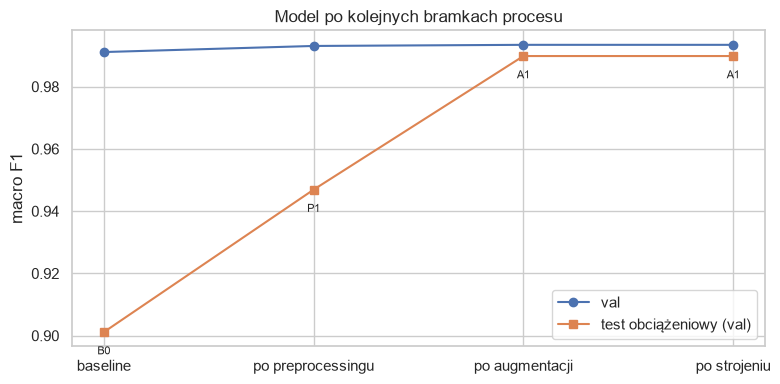

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(steps))
ax.plot(x, journey.val_macro_f1, "o-", label="val")
ax.plot(x, journey.val_stress_macro_f1, "s-", label="test obciążeniowy (val)")
for i, (a, b) in enumerate(zip(journey.index, journey.val_stress_macro_f1)):
    ax.annotate(a, (i, b), xytext=(0, -16), textcoords="offset points", ha="center", fontsize=8)
ax.set_xticks(x, steps); ax.set_ylabel("macro F1"); ax.legend(); ax.set_title("Model po kolejnych bramkach procesu")
plt.tight_layout(); plt.savefig(FIG / "final_journey.png", dpi=150); plt.show()

## Wynik na zbiorze testowym

In [4]:
lm_te, y_te, d_te = load_split("test")
lm_te_st = stress_set(lm_te, seed=456)
pred, pred_st = model.predict(prep(lm_te)), model.predict(prep(lm_te_st))
scores = pd.DataFrame({
    "accuracy": [accuracy_score(y_te, pred), accuracy_score(y_te, pred_st)],
    "macro F1": [f1_score(y_te, pred, average="macro"), f1_score(y_te, pred_st, average="macro")],
}, index=["test", "test obciążeniowy"])
scores.round(4)

,accuracy,macro F1
test,0.9945,0.9943
test obciążeniowy,0.9909,0.9903


In [5]:
print(classification_report(y_te, pred, digits=4))

              precision    recall  f1-score   support

           0     0.9834    0.9947    0.9890      4877
           1     0.9912    0.9948    0.9930     34083
           2     0.9957    0.9916    0.9937     43707
           3     0.9971    0.9967    0.9969     24867
           4     0.9930    0.9968    0.9949      4969
           5     0.9987    0.9979    0.9983     14911

    accuracy                         0.9945    127414
   macro avg     0.9932    0.9954    0.9943    127414
weighted avg     0.9945    0.9945    0.9945    127414



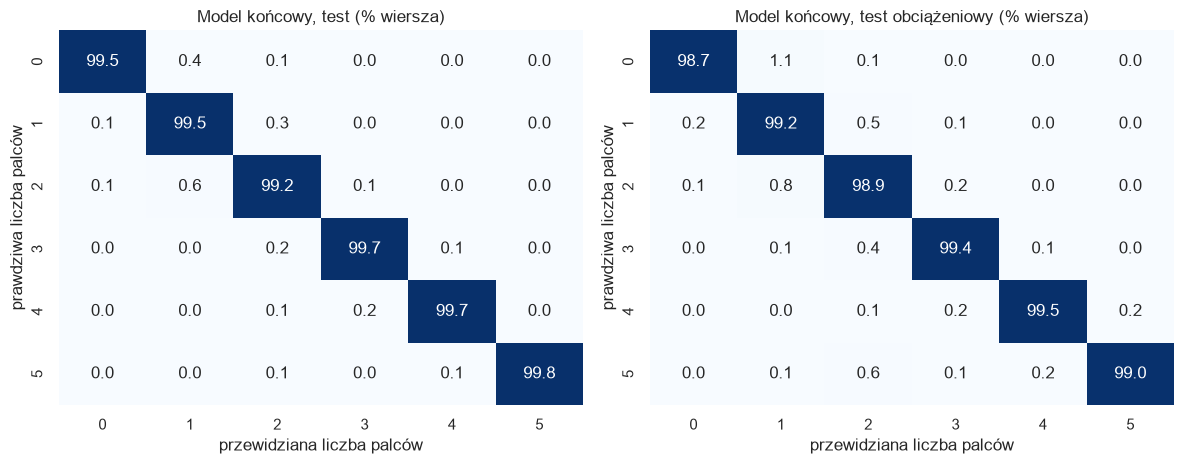

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (p, name) in zip(axes, [(pred, "test"), (pred_st, "test obciążeniowy")]):
    sns.heatmap(confusion_matrix(y_te, p, normalize="true") * 100, annot=True, fmt=".1f", cmap="Blues", ax=ax, cbar=False)
    ax.set(xlabel="przewidziana liczba palców", ylabel="prawdziwa liczba palców", title=f"Model końcowy, {name} (% wiersza)")
plt.tight_layout(); plt.savefig(FIG / "final_confusion.png", dpi=150); plt.show()

## Wyniki na poszczególnych gestach

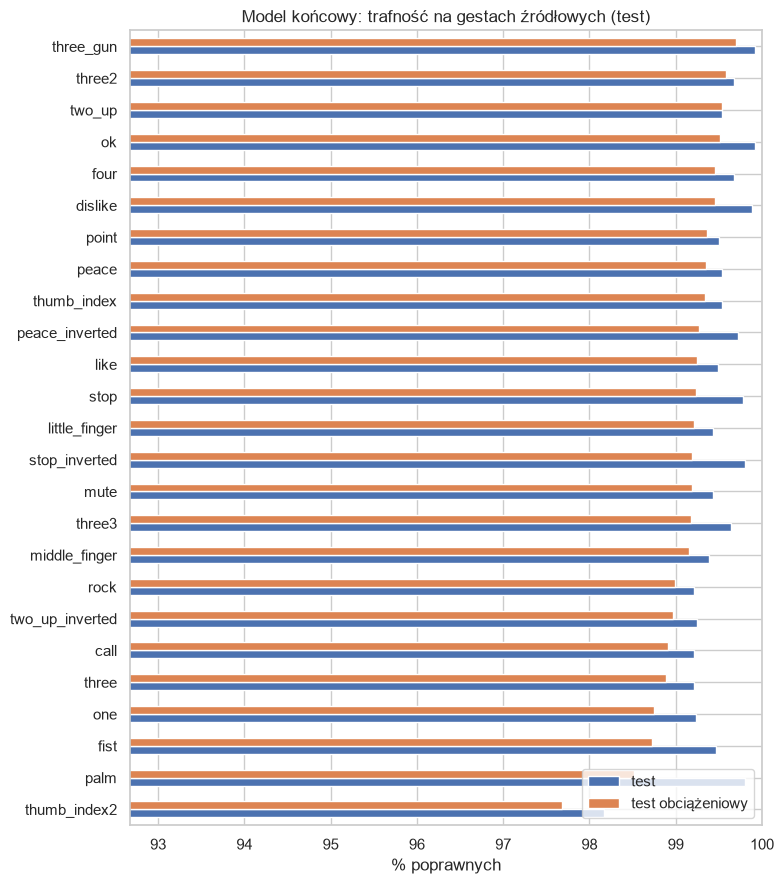

,test,test obciążeniowy,liczba palców
gest,,,
thumb_index2,98.17,97.68,2
palm,99.80,98.52,5
fist,99.47,98.73,0
one,99.23,98.75,1
three,99.21,98.89,3
call,99.21,98.91,2


In [7]:
per_gesture = pd.DataFrame({"gest": d_te.label, "test": pred == y_te, "test obciążeniowy": pred_st == y_te})
per_gesture = per_gesture.groupby("gest").mean().mul(100)
per_gesture["liczba palców"] = per_gesture.index.map(GESTURE_TO_COUNT)
per_gesture = per_gesture.sort_values("test obciążeniowy")
ax = per_gesture[["test", "test obciążeniowy"]].plot.barh(figsize=(8, 9))
ax.set(xlabel="% poprawnych", ylabel="", title="Model końcowy: trafność na gestach źródłowych (test)")
ax.set_xlim(max(0, per_gesture[["test", "test obciążeniowy"]].min().min() - 5), 100)
plt.tight_layout(); plt.savefig(FIG / "final_per_gesture.png", dpi=150); plt.show()
per_gesture.head(6).round(2)

## Czy model działa tak samo dla różnych osób?

Metadane (wiek, płeć, pochodzenie) pochodzą z automatycznego annotatora HaGRID, więc są przybliżone.

In [8]:
meta = pd.read_parquet("../data/interim/images.parquet", columns=["image_id", "age", "gender", "race"])
fair = d_te[["image_id"]].assign(ok=pred == y_te).merge(meta, on="image_id", how="left")
fair["wiek"] = pd.cut(fair.age, [0, 25, 35, 50, 120], labels=["<25", "25-35", "35-50", "50+"])
parts = []
for col, name in [("gender", "płeć"), ("race", "pochodzenie"), ("wiek", "wiek")]:
    g = fair.groupby(col, observed=True).ok.agg(["mean", "size"])
    parts.append(g.assign(cecha=name).rename_axis("grupa").reset_index())
fair_table = pd.concat(parts)
fair_table["trafność %"] = fair_table["mean"].mul(100).round(2)
fair_table[["cecha", "grupa", "size", "trafność %"]].rename(columns={"size": "dłonie"})

,cecha,grupa,dłonie,trafność %
0,płeć,female,69933,99.56
1,płeć,male,57467,99.33
0,pochodzenie,Asian,5323,99.53
1,pochodzenie,Black,6444,98.90
2,pochodzenie,Indian,2592,99.23
3,pochodzenie,White,111304,99.52
0,wiek,<25,34425,99.69
1,wiek,25-35,38890,99.42
2,wiek,35-50,44553,99.41
3,wiek,50+,9532,98.92


## GreenAI całego procesu

Sumujemy wszystkie treningi z `experiments/log.csv` (z każdym ziarnem). Porównanie: samochód benzynowy
emituje około 120 g CO2 na km, pełne naładowanie smartfona to około 15 Wh.

In [9]:
full = pd.read_csv(LOG)
full["runs"] = full.seeds.fillna(1).replace(0, 1)
full.loc[full.process_step == "path exploration", "runs"] = 1
by_step = full.assign(co2=full.co2_g * full.runs, wh=full.energy_kwh * full.runs * 1000,
                      t=full.train_time_s * full.runs).groupby("process_step", sort=False)[["runs", "t", "wh", "co2"]].sum()
by_step.loc["razem"] = by_step.sum()
by_step["metry samochodem"] = by_step.co2 / 120 * 1000
by_step["ładowania telefonu"] = by_step.wh / 15
by_step.rename(columns={"runs": "treningi", "t": "czas [s]", "wh": "energia [Wh]", "co2": "CO2 [g]"}).round(2)

,treningi,czas [s],energia [Wh],CO2 [g],metry samochodem,ładowania telefonu
process_step,,,,,,
path exploration,4.0,98.30,1.10,0.73,6.07,0.07
baseline,3.0,145.70,0.60,0.40,3.31,0.04
preprocessing,12.0,444.77,1.82,1.21,10.05,0.12
augmentation,6.0,661.49,2.69,1.78,14.84,0.18
tuning search,10.0,821.51,3.34,2.21,18.44,0.22
tuning,6.0,592.31,2.41,1.59,13.28,0.16
razem,41.0,2764.07,11.96,7.92,65.99,0.80


In [10]:
x1 = prep(lm_te[:1])
final_info = {"test_macro_f1": float(scores.loc["test", "macro F1"]),
              "test_stress_macro_f1": float(scores.loc["test obciążeniowy", "macro F1"]),
              "model_size_kb": len(pickle.dumps(model)) / 1024, "latency_ms_sklearn": latency_ms(model, x1)}
gates["final"] = {**final, **final_info}
GATES.write_text(json.dumps(gates, indent=2, ensure_ascii=False))
pd.Series(final_info).round(4)

test_macro_f1             0.9943
test_stress_macro_f1      0.9903
model_size_kb           175.2373
latency_ms_sklearn        0.1403
dtype: float64

## Wnioski

- **Wynik na teście: macro F1 0.9943, accuracy 0.9945.** To zbiór, którego żadna decyzja wcześniej nie widziała,
  z innymi osobami niż trening. Wynik jest bliski val (0.9934), więc nie przeuczyliśmy się na val.
- **Test obciążeniowy na zbiorze testowym: 0.9903** (przechylona dłoń, inne proporcje kadru, odbicie, szum).
  Baseline miał na takim teście na val 0.901. Zysk dały prawie po równo preprocessing (+0.046) i augmentacja (+0.043).
- **Najsłabsze gesty to `thumb_index2`, `palm` i `fist`** na teście obciążeniowym (97.7-98.7%). Problemem jest
  kciuk, tak jak w EDA. Najsłabsza klasa to 0 palców (F1 0.989).
- **Grupy osób.** Trafność jest między 98.9% a 99.7% we wszystkich grupach. Najniższa jest dla osób oznaczonych
  jako Black (98.90%) i 50+ (98.92%). Różnica jest mała, ale stała, więc warto ją sprawdzić na własnych nagraniach.
  Metadane są automatyczne, więc to tylko sygnał.
- **GreenAI całego procesu: 41 treningów, 46 minut, 12.0 Wh, 7.92 g CO2.** To jak 66 m jazdy samochodem
  albo 0.8 naładowania smartfona. Najdroższe były augmentacja (1.78 g) i strojenie (3.80 g razem).
- **Pomiar GreenAI ma własny szum.** Łańcuch notebooków uruchomiliśmy kilka razy. Wyniki jakości wychodzą
  identyczne co do cyfry, ale CodeCarbon dał dla A1 0.37 g w przedostatnim i 0.26 g w ostatnim przebiegu.
  Na macOS energia jest szacowana z TDP procesora, więc liczby GreenAI traktujemy jako rząd wielkości.
  Suma nie obejmuje prototypu ani pierwszego przebiegu preprocessingu z błędem w obrocie (opisany w 05).
  Te przebiegi nie trafiły do dziennika, więc prawdziwy koszt jest o kilka gramów wyższy.
- **Model użytkowy jest mały:** 175 KB, 0.14 ms na dłoń na laptopie.